# เทียบโมเดล pitty (ล่าสุด) กับ branch boom — วิดีโอทดสอบของทีมทั้งหมด

วิดีโอ: Google Drive โฟลเดอร์ทดสอบของทีม (`1S375gAp0rc5pAnDKgEyehnO0C9guzU9g`) — **Pitty 7 · Boom 6 · Jack 5 = 18 คลิป**
ดาวน์โหลดไว้ที่ `cache/team_eval/videos/<คน>/` (sha256 ตรงกับ `Boom/phase2.1/06_v82_integration/outputs/eval_inventory.csv` ทุกไฟล์)

**รันบนเครื่องตัวเอง**: checkout branch `pitty` → `git lfs pull` → เปิด notebook นี้ด้วย env `thaislm` → Run All
(ครั้งแรก notebook จะโหลดคลิปจาก Drive ด้วย `gdown` (`pip install gdown`, ต้องมีสิทธิ์เปิดโฟลเดอร์ทีม), ดึงโค้ด `origin/boom` มาไว้ที่
`cache/team_eval/boom_code` แบบอ่านอย่างเดียว (ไม่สลับ branch), ทำ MediaPipe แล้วรันทั้ง 3 โมเดล — ประมาณ 10–15 นาทีบน CPU · `cache/` ไม่ขึ้น Git)

| ชื่อในตาราง | โค้ด | ค่าตั้ง |
|---|---|---|
| **pitty** | branch `pitty` (checkout นี้ — โมเดลล่าสุดของ pitty) | `models/spotting.json` ของ pitty: p_sign_min 0.55 · min_hand_frac 0.3 · accept_min 0.7 |
| **boom_branch** | `origin/boom` (commit ใน `cache/team_eval/boom_code/BOOM_COMMIT.txt`) | `spotting.json` ตามที่อยู่ใน branch: p_sign_min 0.65 · accept_min 0.8 |
| **boom_combined** | `origin/boom` เหมือนกัน | ค่า "Combined" ที่ Boom ล็อกไว้ใน `Boom/phase2.1combined/FROZEN_TEST.json`: p_sign_min 0.55 · act_thr 0.6 · accept_min 0.7 |

* น้ำหนักโมเดล (encoder / tagger / bank / span head) **เหมือนกันทุกไบต์** ทั้งสอง branch — ต่างกันแค่โค้ดใน `modules/` และค่าตั้ง
* hand-shape fusion ของ Boom (`THAISLM_SYMBOLIC_WEIGHT`) ปิดไว้ เหมือนค่า default ใน branch และใน frozen test ของ Boom
* ทุกโมเดลอ่าน **landmark ไฟล์เดียวกัน** (MediaPipe รันครั้งเดียว) → ความต่างมาจากโมเดลเท่านั้น
* vocab = conversation · ไม่ใช้ LLM · สะกดนิ้ว = `en` (เหมือน `my_eval.py`) · CPU + ONNX Runtime · รันทีละโมเดล (latency เทียบกันได้)

**ตัววัด = ชุดเดิมของทีม** (`pitty/scripts/my_eval.py`, `team_metrics_before_after.py`): WER และ คำถูก / ผิด / ขาด / เกิน จาก WER alignment,
Recall@1 / @5 จาก alignment เดียวกัน (ไม่ใช่ "โผล่ตรงไหนก็ได้"), คำที่ยืนยัน (accepted) ถูก / ทั้งหมด, count error, latency
(Segment F1 ต้องมีขอบเขตท่าที่มาร์กด้วยมือ → วิดีโอจริงชุดนี้ไม่มี จึงไม่คำนวณ)

⚠️ **เฉลยของ Boom 6 กับ Jack 5 คลิป ตัดคำจากชื่อไฟล์ตามลำดับประโยคไทย** (`pitty/team_compare/refs.csv`) — ยังไม่ได้ให้เจ้าของคลิปยืนยันลำดับท่า
และมีคำที่ไม่อยู่ใน vocab ของโมเดล 12 คำ (เช่น ไหม จะ กัน แอบ เกม ตลอดไป) ซึ่งไม่มีโมเดลไหนทายถูกได้ — แก้ refs.csv แล้วรันใหม่ได้เลย

In [1]:
import json, subprocess, sys, os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
plt.rcParams['font.family'] = ['Tahoma', 'Leelawadee UI', 'sans-serif']
pd.set_option('display.max_colwidth', 80); pd.set_option('display.width', 250)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'main.py').exists() and (p / 'pitty').exists())   # repo root (Main_demo)
E = ROOT / 'cache/team_eval'
PY = sys.executable                     # env thaislm
RERUN = False                           # True = รันโมเดลใหม่ทุกครั้ง · False = รันเฉพาะโมเดลที่ยังไม่มีผลใน cache/team_eval/results
MODELS = {
    'pitty':         dict(code_root=ROOT, override={}),
    'boom_branch':   dict(code_root=E / 'boom_code', override={}),
    'boom_combined': dict(code_root=E / 'boom_code', override={'post.p_sign_min': 0.55, 'act_thr': 0.6, 'accept_min': 0.7}),
}
print('repo:', ROOT)

repo: C:\Users\ppich\OneDrive\Desktop\tu\yrs4\DSI490\Main_demo


## 1. เตรียมคลิป + โค้ด boom + landmark แล้วรันแต่ละโมเดล (คนละ process เพราะโค้ดทั้งสองชื่อ package `modules` เหมือนกัน)

In [2]:
def sh(args):
    env = dict(os.environ, PYTHONIOENCODING='utf-8')
    p = subprocess.run([PY, str(ROOT / 'pitty/scripts/team_compare.py'), *args], cwd=ROOT, env=env, capture_output=True, text=True, encoding='utf-8')
    out = [l for l in (p.stdout + p.stderr).splitlines() if not l.startswith(('W0000', 'I0000', 'INFO', 'WARNING'))]
    print('\n'.join(out[-25:]))
    assert p.returncode == 0, 'failed'

try:
    import gdown                        # ใช้โหลดคลิปจาก Drive
except ImportError:
    subprocess.run([PY, '-m', 'pip', 'install', '-q', 'gdown'], check=True)
sh(['download'])                        # คลิปที่ยังไม่มีใน cache/team_eval/videos
sh(['setup_boom'])                      # origin/boom → cache/team_eval/boom_code (ข้ามถ้าเป็น commit เดิมอยู่แล้ว)
print('boom commit:', (E / 'boom_code/BOOM_COMMIT.txt').read_text().strip())
sh(['extract'])                         # MediaPipe เฉพาะไฟล์ที่ยังไม่มีใน cache/team_eval/mp
for name, m in MODELS.items():          # ทีละโมเดล ไม่รันพร้อมกัน → latency เทียบกันได้
    if RERUN or not (E / 'results' / name / 'metrics.json').exists():
        print(f'===== {name}')
        sh(['eval', '--label', name, '--code_root', str(m['code_root']), '--override', json.dumps(m['override'])])

boom_code already at a0b4f76a749c2bf1f37f4426973bcf8bc03a848e
boom commit: a0b4f76a749c2bf1f37f4426973bcf8bc03a848e


18 videos → C:\Users\ppich\OneDrive\Desktop\tu\yrs4\DSI490\Main_demo\cache\team_eval\items.json


In [3]:
R = {n: json.loads((E / 'results' / n / 'metrics.json').read_text(encoding='utf-8')) for n in MODELS}
pd.DataFrame({n: r['settings'] for n, r in R.items()}).T.rename_axis('ค่าที่ใช้จริง')

,act_thr,p_sign_min,min_hand_frac,tau_accept,trim_rest,look_alike
ค่าที่ใช้จริง,,,,,,
pitty,0.5,0.55,0.3,0.7,False,False
boom_branch,0.5,0.65,0.0,0.8,False,False
boom_combined,0.6,0.55,0.0,0.7,False,False


## 2. สรุปรวม และแยกตามคนที่อัดวิดีโอ

In [4]:
V = pd.concat([pd.DataFrame(r['videos']).assign(model=n) for n, r in R.items()], ignore_index=True)

def summarise(x):
    n = x.n_ref.sum(); acc = x.accepted_n.sum()
    return pd.Series({'คลิป': len(x), 'คำเฉลย': n, 'WER (เฉลี่ยต่อคลิป)': x.WER.mean(), 'WER (รวมทุกคำ)': (x.wrong + x.missing + x.extra).sum() / n,
                      'ถูก': f"{x.right.sum()}/{n}", 'ผิด': x.wrong.sum(), 'ขาด': x.missing.sum(), 'เกิน': x.extra.sum(),
                      'Recall@1': x.right.sum() / n, 'Recall@5': x.top5_hit.sum() / n,
                      'ยืนยันถูก': f"{x.accepted_correct.sum()}/{acc}", 'precision ที่ยืนยัน': x.accepted_correct.sum() / acc if acc else float('nan'),
                      'ยืนยันได้ (% ของคำเฉลย)': acc / n, 'count error': x.count_err.mean(), 'latency (s, median)': x.latency_s.median(),
                      'คำนอก vocab': x.n_oov.sum(), 'WER ไม่นับคำนอก vocab': x.WER_known.mean()})

order = list(MODELS)
S = pd.concat([V.groupby('model')[V.columns.drop('model')].apply(summarise).assign(ชุด='ทั้งหมด 18 คลิป')] +
              [V[V.person == p].groupby('model')[V.columns.drop('model')].apply(summarise).assign(ชุด=f'{p}') for p in ['Pitty', 'Boom', 'Jack']])
S = S.reset_index().set_index(['ชุด', 'model']).reindex([(s, m) for s in ['ทั้งหมด 18 คลิป', 'Pitty', 'Boom', 'Jack'] for m in order])
S.style.format({c: '{:.3f}' for c in ['WER (เฉลี่ยต่อคลิป)', 'WER (รวมทุกคำ)', 'Recall@1', 'Recall@5', 'precision ที่ยืนยัน', 'ยืนยันได้ (% ของคำเฉลย)',
                                      'count error', 'latency (s, median)', 'WER ไม่นับคำนอก vocab']})

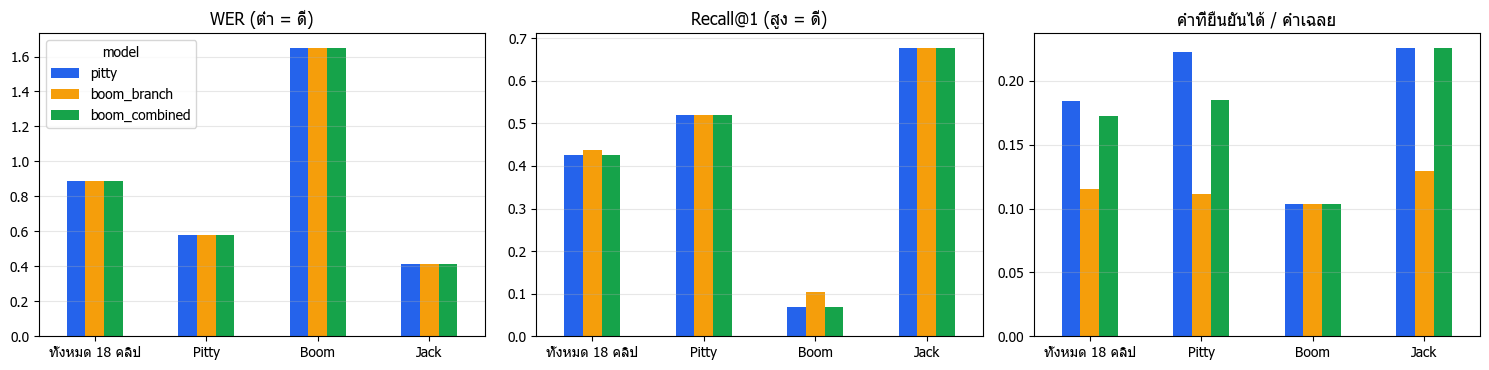

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cols = {'pitty': '#2563eb', 'boom_branch': '#f59e0b', 'boom_combined': '#16a34a'}
for k, (metric, title) in enumerate([('WER (เฉลี่ยต่อคลิป)', 'WER (ต่ำ = ดี)'), ('Recall@1', 'Recall@1 (สูง = ดี)'), ('ยืนยันได้ (% ของคำเฉลย)', 'คำที่ยืนยันได้ / คำเฉลย')]):
    t = S[metric].astype(float).unstack('model')[order].reindex(['ทั้งหมด 18 คลิป', 'Pitty', 'Boom', 'Jack'])
    t.plot.bar(ax=ax[k], color=[cols[m] for m in order], rot=0, legend=(k == 0)); ax[k].set_title(title); ax[k].set_xlabel('')
    ax[k].grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()

## 3. ผลต่อคลิป — คำที่แต่ละโมเดลอ่านได้ (top-1) เทียบกับเฉลย

In [6]:
P = V.pivot_table(index=['person', 'video'], columns='model', values=['WER', 'right', 'accepted_n', 'accepted_correct'], aggfunc='first')
T = V.pivot_table(index=['person', 'video'], columns='model', values=['top1', 'accepted'], aggfunc='first')
ref = V.drop_duplicates(['person', 'video']).set_index(['person', 'video'])[['ref', 'n_oov']]
tab = ref.copy()
for m in order:
    tab[f'{m} · top-1'] = T[('top1', m)]
    tab[f'{m} · WER'] = P[('WER', m)].round(2)
    tab[f'{m} · ยืนยัน'] = P[('accepted_correct', m)].astype(int).astype(str) + '/' + P[('accepted_n', m)].astype(int).astype(str)
tab.reindex(['Pitty', 'Boom', 'Jack'], level=0)

ref  n_oov                                pitty · top-1  pitty · WER pitty · ยืนยัน                             boom_branch · top-1  boom_branch · WER  \
person video                                                                                                                                                                                                                                    
Pitty  พรุ่งนี้ฉันไปโรงเรียน                                      พรุ่งนี้ ฉัน ไป โรงเรียน      0             แฟน สวัสดี ฉัน ยาย โรงเรียน ข้าว         1.00            0/0                แฟน สวัสดี ฉัน ยาย โรงเรียน ข้าว               1.00   
       สวัสดีฉันชื่อ P                                                   สวัสดี ฉัน ชื่อ P      0                            สวัสดี ฉัน ชื่อ P         0.00            3/3                               สวัสดี ฉัน ชื่อ P               0.00   
       ฉันคิดถึงแม่                                                         ฉัน คิดถึง แม่      0                                      ฉัน แม่         0.33            1/1                                         ฉัน แม่               0.33   
       ฉันชอบกินขนมปัง                                                  ฉัน ชอบ กิน ขนมปัง      0                               ฉัน กิน ขนมปัง         0.25            0/0                                  ฉัน กิน ขนมปัง               0.25   
       พรุ่งนี้ฉันไปเที่ยว                                          พรุ่งนี้ ฉัน ไป เที่ยว      0                                  น้อง เที่ยว         0.75            0/0                                     น้อง เที่ยว               0.75   
       ฉันรักเพื่อน                                                         ฉัน รัก เพื่อน      0                              ฉัน เกิด เพื่อน         0.33            2/2                                 ฉัน เกิด เพื่อน               0.33   
       วันหยุดพ่อชอบไปตลาด                                         วันหยุด พ่อ ชอบ ไป ตลาด      0          เที่ยว ไป กิน ฉัน เพื่อน แม่ ขนมปัง         1.40            0/0             เที่ยว ไป กิน ฉัน เพื่อน แม่ ขนมปัง               1.40   
Boom   ฉันยังลืมคุณไม่ได้                                           ฉัน ยัง ลืม คุณ ไม่ได้      0                ยาย ไป คุณ ชอบ ญาติ เป็น อย่า         1.40            0/0                   ยาย ไป คุณ ชอบ ญาติ เป็น อย่า               1.40   
       ฉันแอบชอบคุณ                                                        ฉัน แอบ ชอบ คุณ      1       แฟน แต่งงาน เกิด แต่งงาน เกิด ข้าว ถาม         1.75            0/0          แฟน แต่งงาน เกิด แต่งงาน เกิด ข้าว ถาม               1.75   
       ตอนนี้กำลังเรียนภาษา                                        ตอนนี้ กำลัง เรียน ภาษา      0    วันนี้ เรียน กรุงเทพ คุณ ตอนนี้ เรียน คุณ         1.50            1/1  เกิด ตอนนี้ เรียน กรุงเทพ คุณ ตอนนี้ เรียน คุณ               1.50   
       มีอะไรให้ฉันช่วยไหม                                        มี อะไร ให้ ฉัน ช่วย ไหม      1       เกิด กิน เกิด สิบ I กิน ไข่ ตลาด ยาย I         1.67            0/0          เกิด กิน เกิด สิบ I กิน ไข่ ตลาด ยาย I               1.67   
       เราจะเป็นเพื่อนกันตลอดไป                              เรา จะ เป็น เพื่อน กัน ตลอดไป      3  ภรรยา ไป แฟน เพื่อน กิน ข้าว คุณ เพื่อน กิน         1.33            2/2     ภรรยา ไป แฟน เพื่อน กิน ข้าว คุณ เพื่อน กิน               1.33   
       เล่นเกมส์กันไหม                                                    เล่น เกม กัน ไหม      3        ญาติ เกิด ถูก ญาติ ข้าว I ญาติ เกิด I         2.25            0/0           ญาติ เกิด ถูก ญาติ ข้าว I ญาติ เกิด I               2.25   
Jack   ฉันสบายดี คุณสบายดี_                                          ฉัน สบายดี คุณ สบายดี      0                        ฉัน สบายดี แฟน สบายดี         0.25            0/0                           ฉัน สบายดี แฟน สบายดี               0.25   
       พรุ่งนี้ผมจะไปเที่ยวประเทศจีน                    พรุ่งนี้ ผม จะ ไป เที่ยว ประเทศจีน      2  พรุ่งนี้ ฉัน ไป เที่ยว กรุงเทพ แต่งงาน เกิด         0.83            0/0     พรุ่งนี้ ฉัน ไป เที่ยว กรุงเทพ แต่งงาน เกิด             

## 3b. คำเกิน / คำขาด / คำผิด — นับต่อคลิป

จาก WER alignment เดียวกับที่ใช้คิด WER: **ถูก** = ตรงตำแหน่งกับเฉลย · **ผิด** = มีท่าตรงตำแหน่งนั้นแต่ทายเป็นคำอื่น ·
**ขาด** = คำในเฉลยที่โมเดลไม่ได้อ่านออกมาเลย · **เกิน** = คำที่โมเดลอ่านออกมาแต่ไม่มีในเฉลย (มักเป็นช่วงพักหรือท่าเปลี่ยนที่ถูกอ่านเป็นคำ)

In [7]:
cnt = V.set_index(['person', 'video', 'model'])[['n_ref', 'n_seg', 'right', 'wrong', 'missing', 'extra']]
cnt.columns = ['คำเฉลย', 'คำที่อ่านได้', 'ถูก', 'ผิด', 'ขาด', 'เกิน']
C = cnt.drop(columns=['คำเฉลย']).unstack('model').swaplevel(axis=1)[order]
C.insert(0, ('', 'คำเฉลย'), cnt['คำเฉลย'].groupby(['person', 'video']).first())
tot = C.groupby(level='person').sum(); tot.index = pd.MultiIndex.from_tuples([(p, '◆ รวม') for p in tot.index], names=C.index.names)
allt = C.sum().to_frame().T; allt.index = pd.MultiIndex.from_tuples([('ทั้งหมด', '◆ รวม 18 คลิป')], names=C.index.names)
C = pd.concat([pd.concat([C.loc[[p]], tot.loc[[p]]]) for p in ['Pitty', 'Boom', 'Jack']] + [allt])
C.style.apply(lambda r: ['font-weight:bold; background:#f1f5f9' if r.name[1].startswith('◆') else '' for _ in r], axis=1)

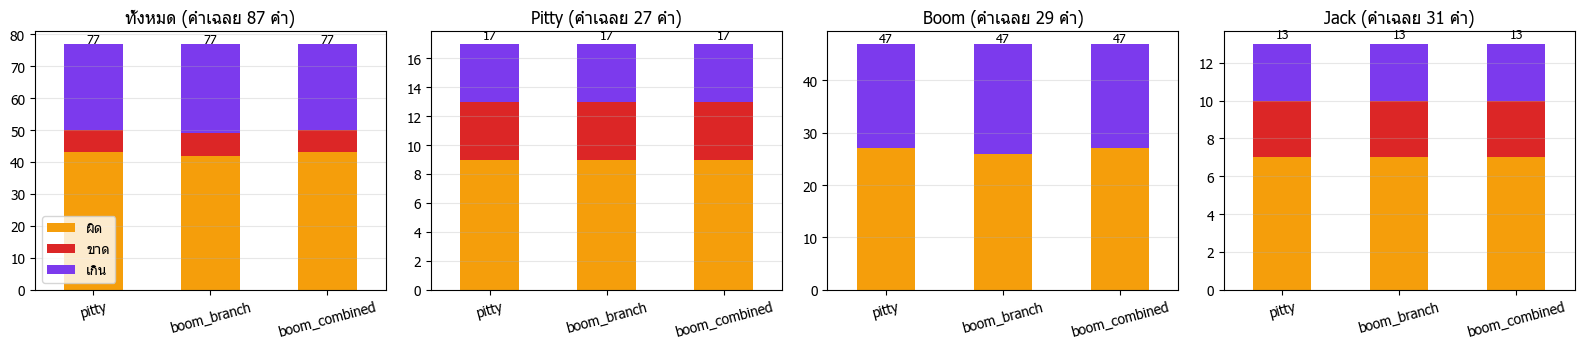

In [8]:
# จำนวนคำผิด / ขาด / เกิน รวมต่อคน (ซ้อนกันเป็นแท่ง; สูงรวม = จำนวนคำที่ต้องแก้ทั้งหมด)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), sharey=False)
for k, p in enumerate(['ทั้งหมด', 'Pitty', 'Boom', 'Jack']):
    x = V if p == 'ทั้งหมด' else V[V.person == p]
    t = x.groupby('model')[['wrong', 'missing', 'extra']].sum().reindex(order).rename(columns={'wrong': 'ผิด', 'missing': 'ขาด', 'extra': 'เกิน'})
    t.plot.bar(stacked=True, ax=ax[k], color=['#f59e0b', '#dc2626', '#7c3aed'], rot=15, legend=(k == 0))
    ax[k].set_title(f"{p} (คำเฉลย {x.drop_duplicates(['person', 'video']).n_ref.sum()} คำ)"); ax[k].set_xlabel(''); ax[k].grid(axis='y', alpha=.3)
    for i, (_, r) in enumerate(t.iterrows()):
        ax[k].text(i, r.sum() + .3, int(r.sum()), ha='center', fontsize=9)
plt.tight_layout(); plt.show()

### คำไหนขาด คำไหนเกิน คำไหนผิด (ต่อคลิป ต่อโมเดล)

`ผิด` เขียนเป็น เฉลย→ที่โมเดลอ่าน · คำที่มี * คือคำที่ไม่อยู่ใน vocab ของโมเดล (ไม่มีทางทายถูก)

In [9]:
sys.path.insert(0, str(ROOT / 'pitty/scripts')); from wer_ops import align
items = {(it['person'], Path(it['file']).stem): it for it in json.loads((E / 'items.json').read_text(encoding='utf-8'))}
W = []
for _, r in V.iterrows():
    it = items[(r.person, r.video)]; oov = {w for w, k in zip(it['ref'], it['known']) if not k}
    star = lambda w: f'{w}*' if w in oov else w
    ops = align(r.ref.split(), r.top1.split())
    W.append(dict(person=r.person, video=r.video, model=r.model, เฉลย=' '.join(star(w) for w in r.ref.split()), โมเดลอ่านว่า=r.top1,
                  ขาด=', '.join(star(o[1]) for o in ops if o[0] == 'D') or '–',
                  เกิน=', '.join(o[2] for o in ops if o[0] == 'I') or '–',
                  ผิด=', '.join(f'{star(o[1])}→{o[2]}' for o in ops if o[0] == 'S') or '–'))
W = pd.DataFrame(W)
W['model'] = pd.Categorical(W.model, order); W['person'] = pd.Categorical(W.person, ['Pitty', 'Boom', 'Jack'])
W.sort_values(['person', 'video', 'model']).set_index(['person', 'video', 'model'])

เฉลย                                    โมเดลอ่านว่า            ขาด                         เกิน  \
person video                                 model                                                                                                                                                       
Pitty  ฉันคิดถึงแม่                          pitty                                          ฉัน คิดถึง แม่                                         ฉัน แม่         คิดถึง                            –   
                                             boom_branch                                    ฉัน คิดถึง แม่                                         ฉัน แม่         คิดถึง                            –   
                                             boom_combined                                  ฉัน คิดถึง แม่                                         ฉัน แม่         คิดถึง                            –   
       ฉันชอบกินขนมปัง                       pitty                                      ฉัน ชอบ กิน ขนมปัง                                  ฉัน กิน ขนมปัง            ชอบ                            –   
                                             boom_branch                                ฉัน ชอบ กิน ขนมปัง                                  ฉัน กิน ขนมปัง            ชอบ                            –   
                                             boom_combined                              ฉัน ชอบ กิน ขนมปัง                                  ฉัน กิน ขนมปัง            ชอบ                            –   
       ฉันรักเพื่อน                          pitty                                          ฉัน รัก เพื่อน                                 ฉัน เกิด เพื่อน              –                            –   
                                             boom_branch                                    ฉัน รัก เพื่อน                                 ฉัน เกิด เพื่อน              –                            –   
                                             boom_combined                                  ฉัน รัก เพื่อน                                 ฉัน เกิด เพื่อน              –                            –   
       พรุ่งนี้ฉันไปเที่ยว                   pitty                                  พรุ่งนี้ ฉัน ไป เที่ยว                                     น้อง เที่ยว  พรุ่งนี้, ฉัน                            –   
                                             boom_branch                            พรุ่งนี้ ฉัน ไป เที่ยว                                     น้อง เที่ยว  พรุ่งนี้, ฉัน                            –   
                                             boom_combined                          พรุ่งนี้ ฉัน ไป เที่ยว                                     น้อง เที่ยว  พรุ่งนี้, ฉัน                            –   
       พรุ่งนี้ฉันไปโรงเรียน                 pitty                                พรุ่งนี้ ฉัน ไป โรงเรียน                แฟน สวัสดี ฉัน ยาย โรงเรียน ข้าว              –                    แฟน, ข้าว   
                                             boom_branch                          พรุ่งนี้ ฉัน ไป โรงเรียน                แฟน สวัสดี ฉัน ยาย โรงเรียน ข้าว              –                    แฟน, ข้าว   
                                             boom_combined                        พรุ่งนี้ ฉัน ไป โรงเรียน                แฟน สวัสดี ฉัน ยาย โรงเรียน ข้าว              –                    แฟน, ข้าว   
       วันหยุดพ่อชอบไปตลาด                   pitty                                 วันหยุด พ่อ ชอบ ไป ตลาด             เที่ยว ไป กิน ฉัน เพื่อน แม่ ขนมปัง              –                   เที่ยว, ไป   
                                             boom_branch                           วันหยุด พ่อ ชอบ ไป ตลาด             เที่ยว ไป กิน ฉัน เพื่อน แม่ ขนมปัง              –                   เที่ยว, ไป   
                                             boom_combined                         วันหยุด พ่อ ชอบ ไป ตลาด             เที่ยว ไป กิน ฉัน เพื่อน แม่ ขนมปัง              –                   เที่ยว, ไป   
       สวัสดีฉันชื่อ P                       pitty            

In [10]:
# คำที่ขาดบ่อย / เกินบ่อย รวมทุกคลิป แยกโมเดล
def top(col):
    out = {}
    for m in order:
        s = W[W.model == m][col].str.split(', ').explode()
        vc = s[s != '–'].str.replace(r'→.*', '', regex=True).value_counts().head(10)
        out[m] = pd.Series([f'{w} ({n})' for w, n in vc.items()])
    return pd.DataFrame(out).fillna('')
display(Markdown('**คำที่ขาดบ่อยที่สุด** (คำ (จำนวนครั้ง))')); display(top('ขาด'))
display(Markdown('**คำที่เกินบ่อยที่สุด**')); display(top('เกิน'))
display(Markdown('**คำในเฉลยที่ถูกทายผิดบ่อยที่สุด**')); display(top('ผิด'))

**คำที่ขาดบ่อยที่สุด** (คำ (จำนวนครั้ง))

,pitty,boom_branch,boom_combined
0,คิดถึง (1),คิดถึง (1),คิดถึง (1)
1,ชอบ (1),ชอบ (1),ชอบ (1)
2,พรุ่งนี้ (1),พรุ่งนี้ (1),พรุ่งนี้ (1)
3,ฉัน (1),ฉัน (1),ฉัน (1)
4,ผม (1),ผม (1),ผม (1)
5,นำเสนอ (1),นำเสนอ (1),นำเสนอ (1)
6,กับ* (1),กับ* (1),กับ* (1)


**คำที่เกินบ่อยที่สุด**

,pitty,boom_branch,boom_combined
0,เกิด (4),เกิด (5),เกิด (5)
1,ข้าว (3),ข้าว (3),แฟน (3)
2,กิน (3),กิน (3),ไป (3)
3,แฟน (2),แฟน (2),ข้าว (2)
4,ไป (2),ไป (2),แต่งงาน (2)
5,แต่งงาน (2),แต่งงาน (2),กรุงเทพ (2)
6,กรุงเทพ (2),กรุงเทพ (2),กิน (2)
7,ญาติ (2),คุณ (2),ญาติ (2)
8,เที่ยว (1),ญาติ (2),เที่ยว (1)
9,ยาย (1),เที่ยว (1),ยาย (1)


**คำในเฉลยที่ถูกทายผิดบ่อยที่สุด**

,pitty,boom_branch,boom_combined
0,คุณ (3),คุณ (3),ไป (3)
1,ไป (3),ไป (3),ฉัน (3)
2,ฉัน (3),ฉัน (3),คุณ (3)
3,ไหม* (2),ไหม* (2),จะ* (2)
4,จะ* (2),จะ* (2),ชอบ (2)
5,ชอบ (2),ชอบ (2),กัน* (2)
6,กัน* (2),กัน* (2),ไหม* (2)
7,เรา (1),เรา (1),พรุ่งนี้ (1)
8,เป็น (1),เป็น (1),ตลอดไป* (1)
9,ตลอดไป* (1),ตลอดไป* (1),เป็น (1)


### คลิปที่โมเดลให้ผลต่างกัน

In [11]:
diff = []
for (p, v), g in V.groupby(['person', 'video']):
    g = g.set_index('model')
    if g.top1.nunique() > 1 or g.accepted.nunique() > 1:
        diff.append(dict(person=p, video=v, ref=g.ref.iloc[0], **{f'{m} top-1': g.top1[m] for m in order}, **{f'{m} ยืนยัน': g.accepted[m] for m in order}))
D = pd.DataFrame(diff)
display(Markdown(f'**{len(D)} / {V.groupby(["person", "video"]).ngroups} คลิป** ที่คำ top-1 หรือคำที่ยืนยันต่างกันอย่างน้อยหนึ่งโมเดล'))
D

**6 / 18 คลิป** ที่คำ top-1 หรือคำที่ยืนยันต่างกันอย่างน้อยหนึ่งโมเดล

,person,video,ref,pitty top-1,boom_branch top-1,boom_combined top-1,pitty ยืนยัน,boom_branch ยืนยัน,boom_combined ยืนยัน
0,Boom,ตอนนี้กำลังเรียนภาษา,ตอนนี้ กำลัง เรียน ภาษา,วันนี้ เรียน กรุงเทพ คุณ ตอนนี้ เรียน คุณ,เกิด ตอนนี้ เรียน กรุงเทพ คุณ ตอนนี้ เรียน คุณ,เกิด ตอนนี้ เรียน กรุงเทพ คุณ ตอนนี้ เรียน คุณ,เรียน,เรียน,เรียน
1,Boom,มีอะไรให้ฉันช่วยไหม,มี อะไร ให้ ฉัน ช่วย ไหม,เกิด กิน เกิด สิบ I กิน ไข่ ตลาด ยาย I,เกิด กิน เกิด สิบ I กิน ไข่ ตลาด ยาย I,เกิด กิน เกิด สิบ I กิน เกิด ตลาด ยาย I,,,
2,Boom,เราจะเป็นเพื่อนกันตลอดไป,เรา จะ เป็น เพื่อน กัน ตลอดไป,ภรรยา ไป แฟน เพื่อน กิน ข้าว คุณ เพื่อน กิน,ภรรยา ไป แฟน เพื่อน กิน ข้าว คุณ เพื่อน กิน,ไป แฟน เพื่อน กิน ข้าว คุณ เพื่อน กิน,เพื่อน เพื่อน,เพื่อน เพื่อน,เพื่อน เพื่อน
3,Jack,สวัสดี ฉันชื่อ J ฉันชอบแมว,สวัสดี ฉัน ชื่อ J ฉัน ชอบ แมว,สวัสดี ฉัน ชื่อ J ฉัน ชอบ กิน แมว,สวัสดี ฉัน ชื่อ J ฉัน ชอบ กิน แมว,สวัสดี ฉัน ชื่อ J ฉัน ชอบ กิน แมว,สวัสดี ฉัน ฉัน ชอบ แมว,ฉัน ชอบ,สวัสดี ฉัน ฉัน ชอบ แมว
4,Pitty,ฉันคิดถึงแม่,ฉัน คิดถึง แม่,ฉัน แม่,ฉัน แม่,ฉัน แม่,ฉัน,,
5,Pitty,สวัสดีฉันชื่อ P,สวัสดี ฉัน ชื่อ P,สวัสดี ฉัน ชื่อ P,สวัสดี ฉัน ชื่อ P,สวัสดี ฉัน ชื่อ P,สวัสดี ฉัน ชื่อ,สวัสดี,สวัสดี ฉัน ชื่อ


## 4. Timeline ค่า confidence ต่อท่า (เหมือน phase 8)

ต่อคลิป: ภาพกลางท่า · เวลา · P(ถูก) สีตามสถานะ (เขียว = ยืนยัน · เหลือง = ไม่แน่ใจ · แดง = ไม่รู้จัก) · คำ top-3
แสดง pitty คู่กับ boom_combined (ค่าที่ Boom ล็อกไว้); รูปของ boom_branch อยู่ใน `cache/team_eval/results/boom_branch/`

### Pitty

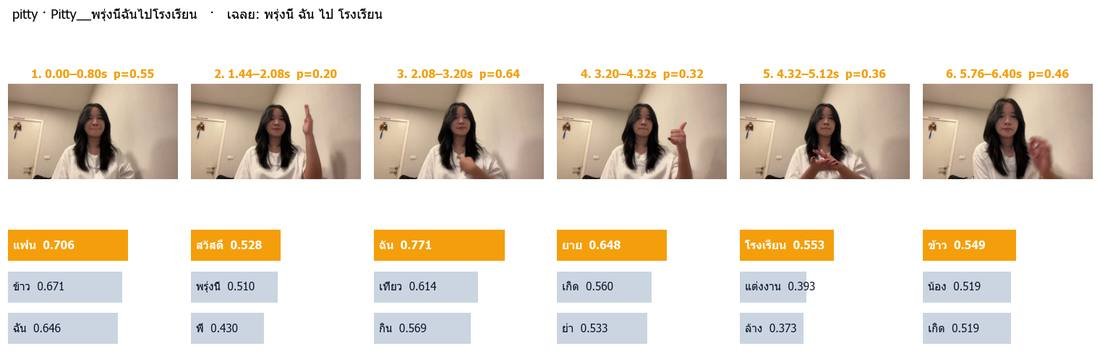

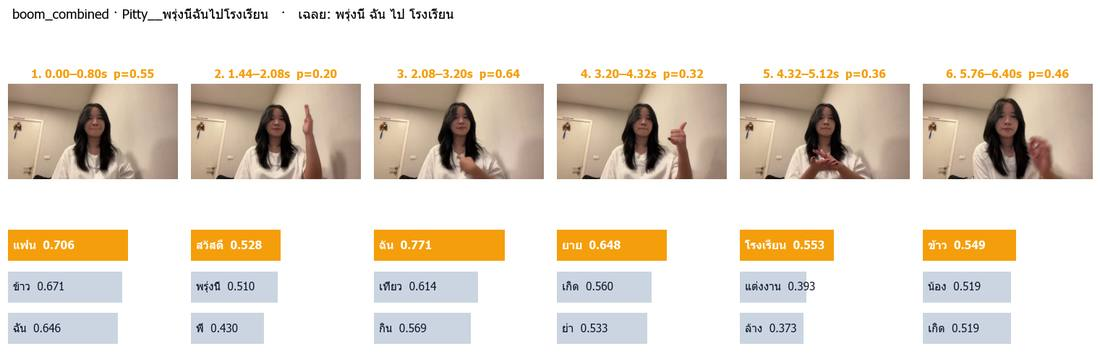

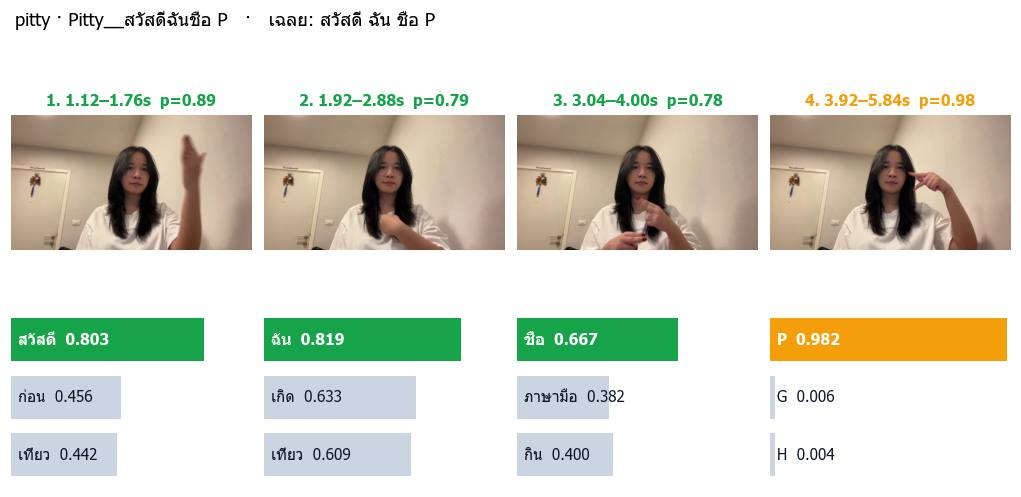

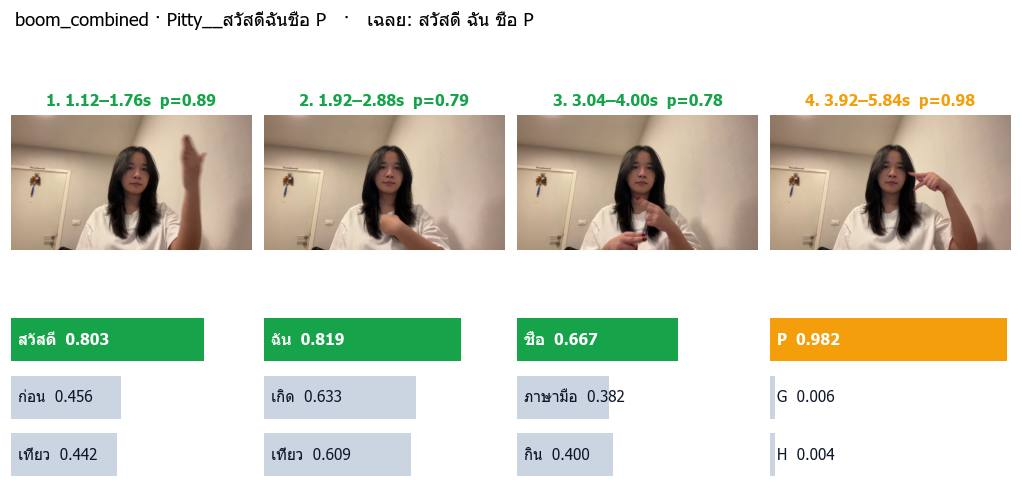

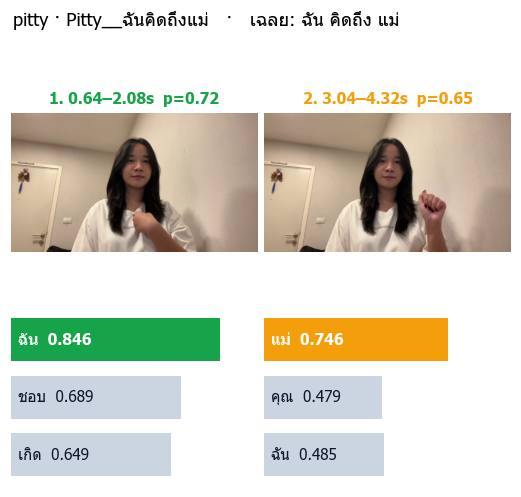

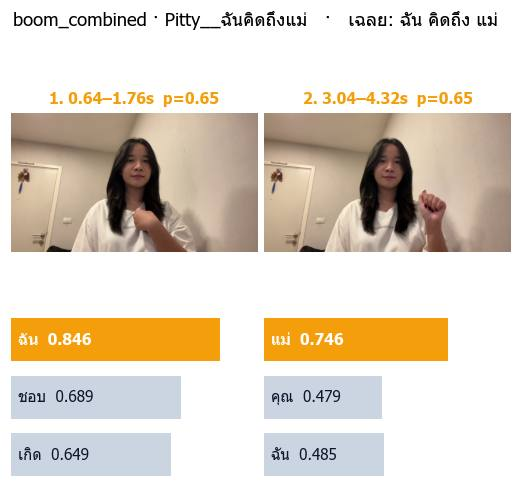

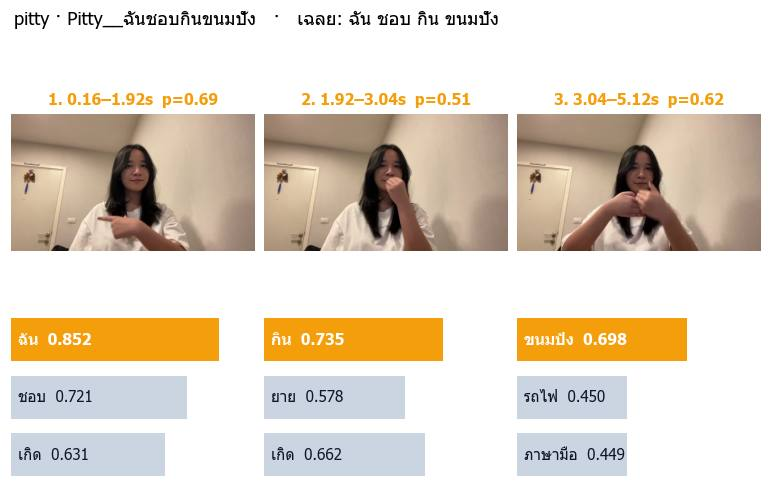

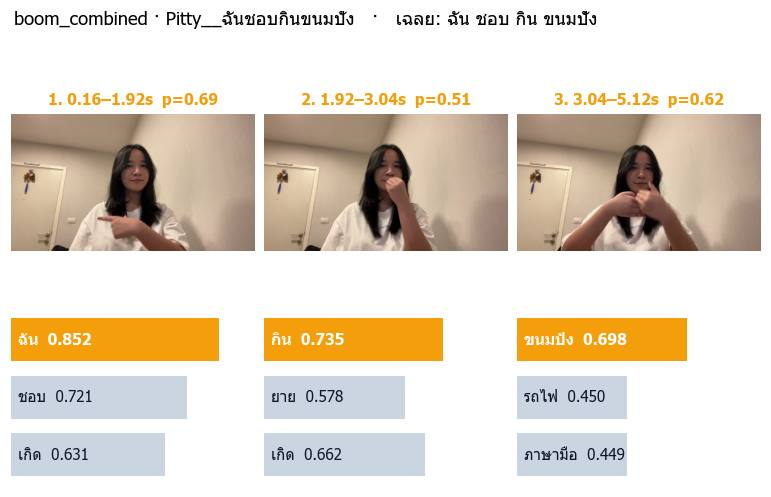

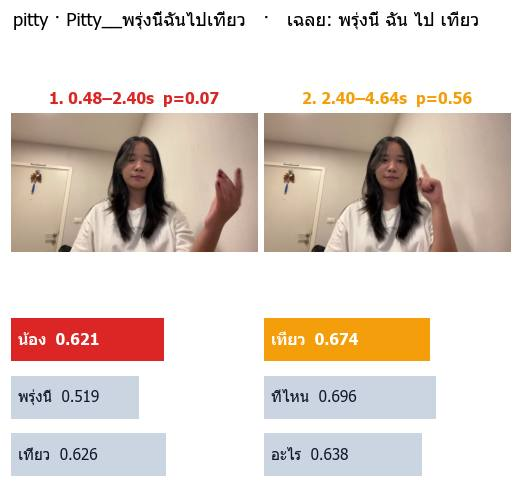

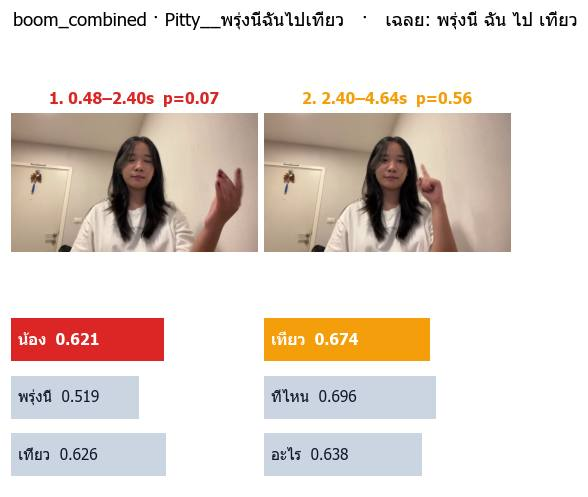

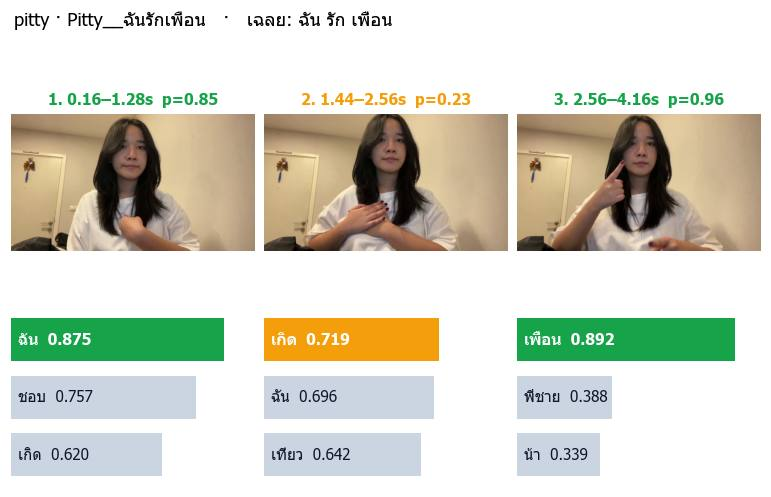

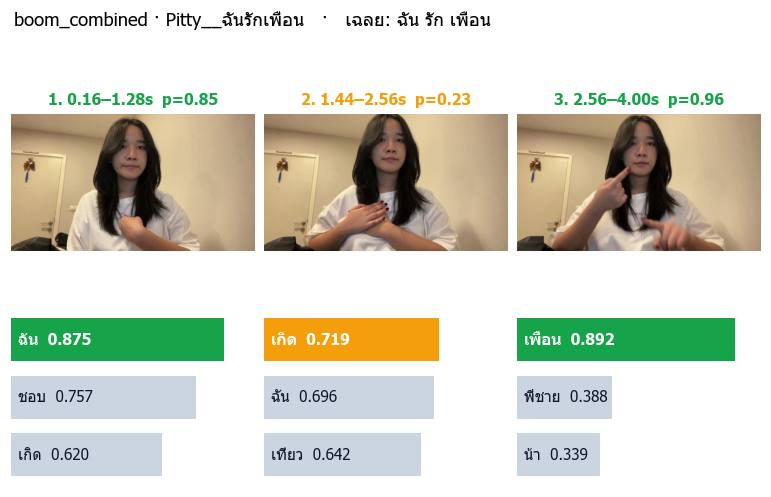

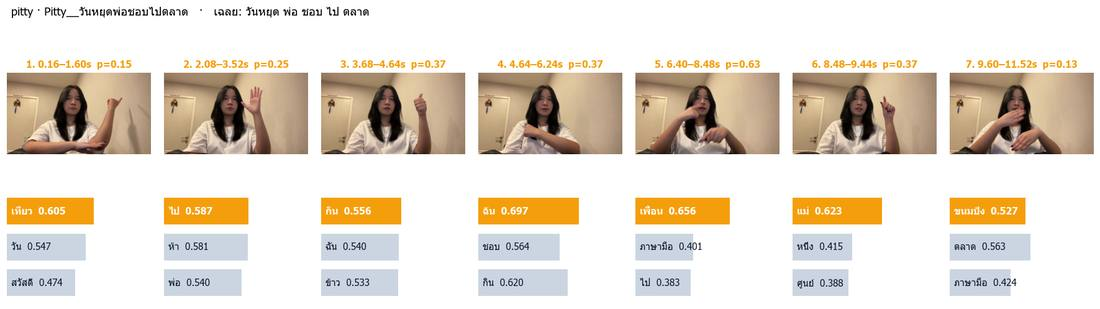

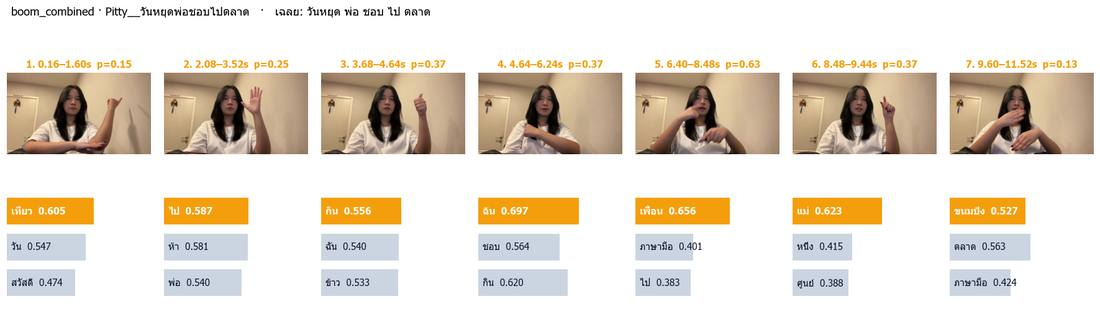

### Boom

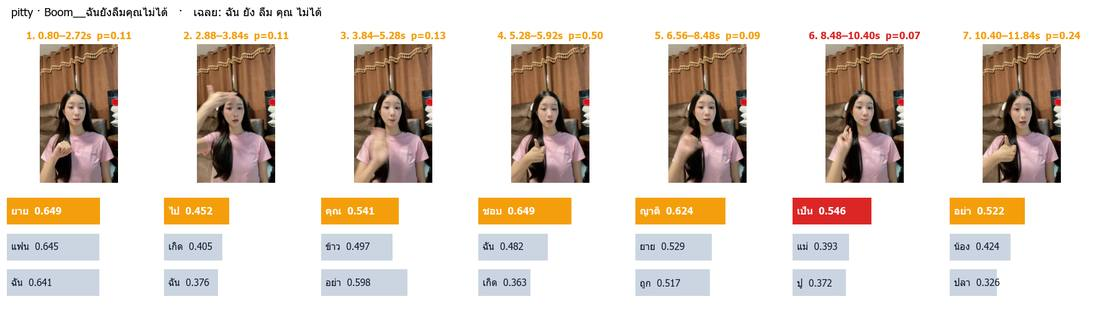

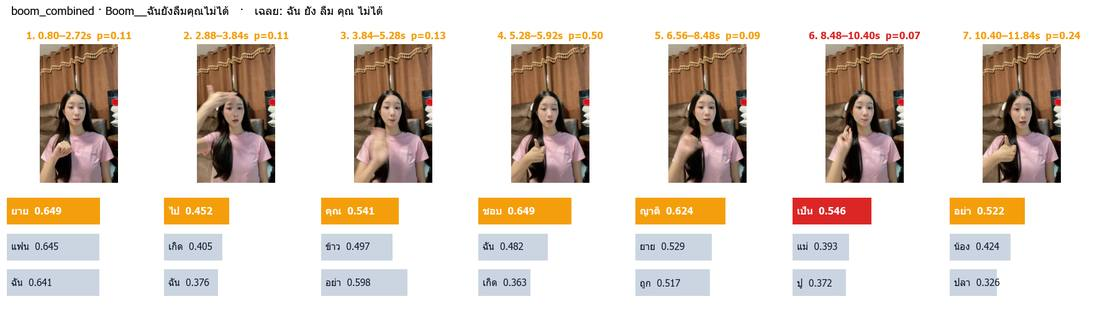

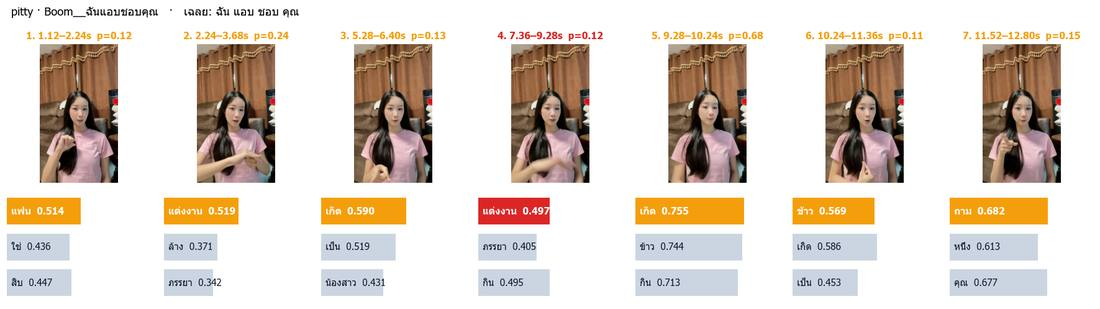

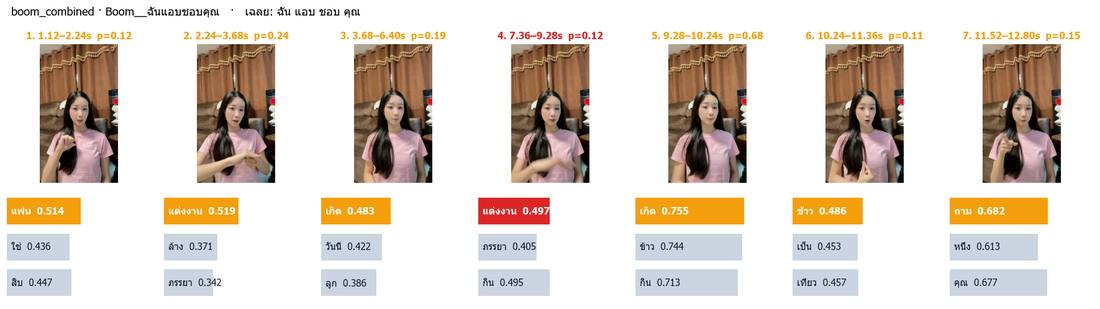

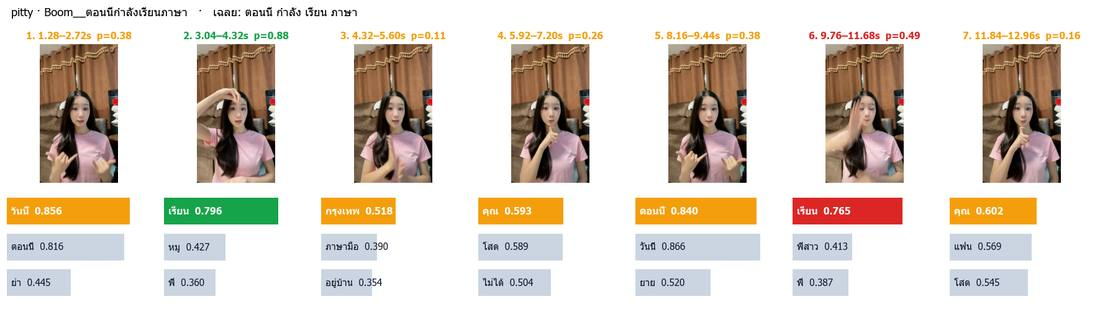

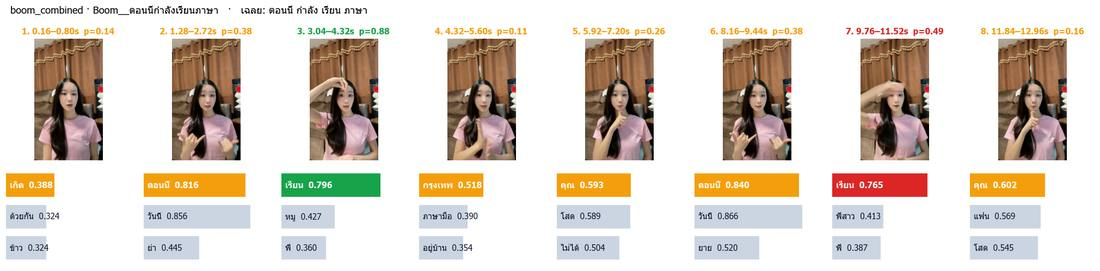

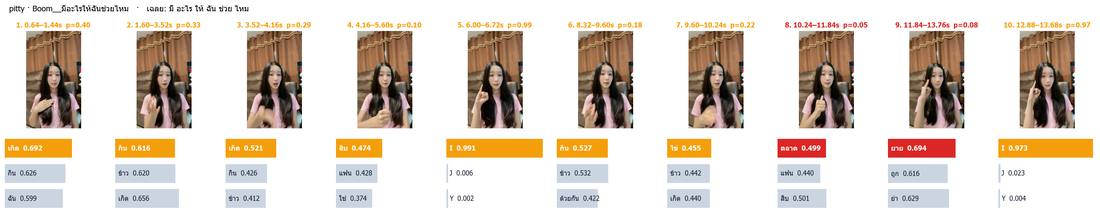

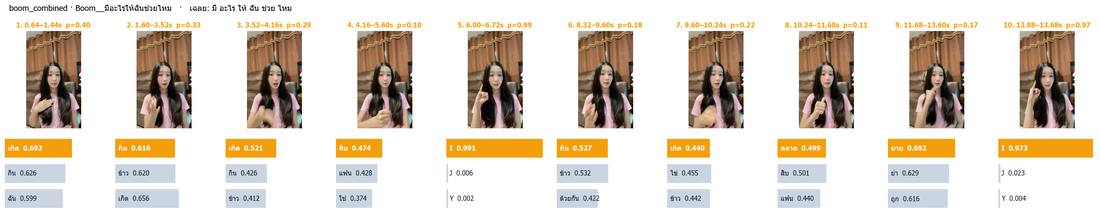

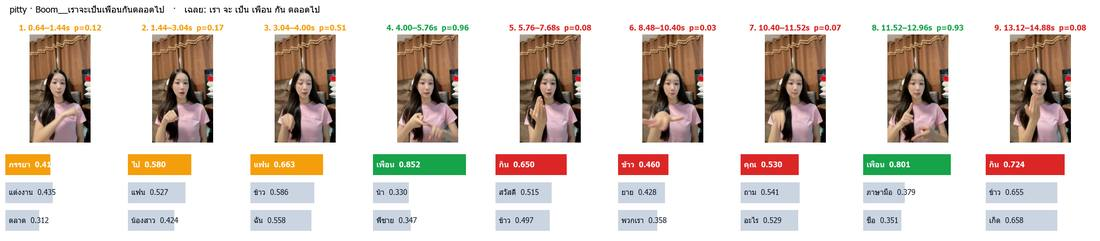

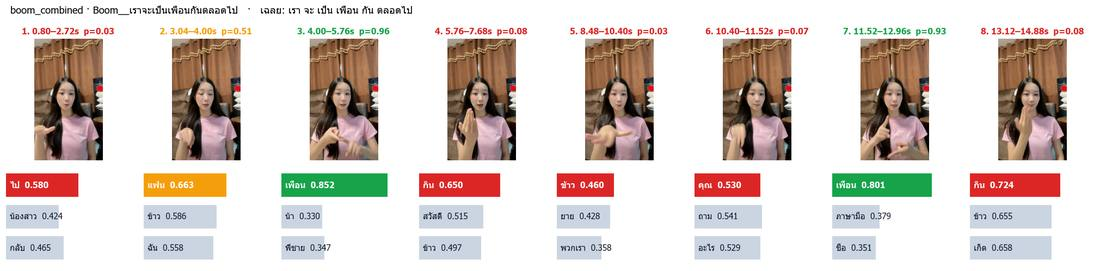

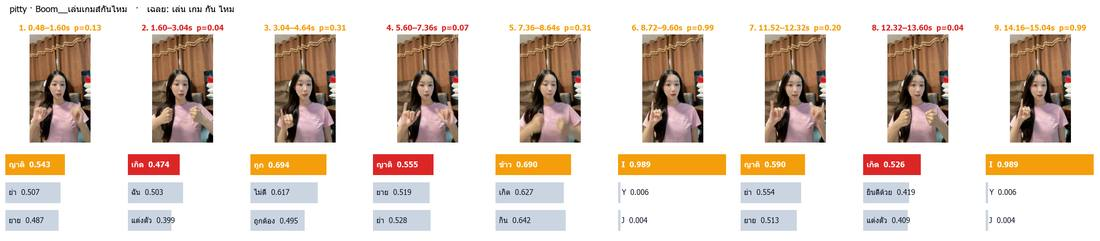

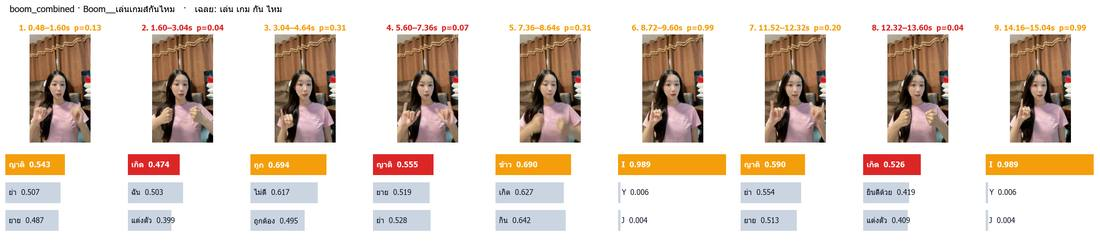

### Jack

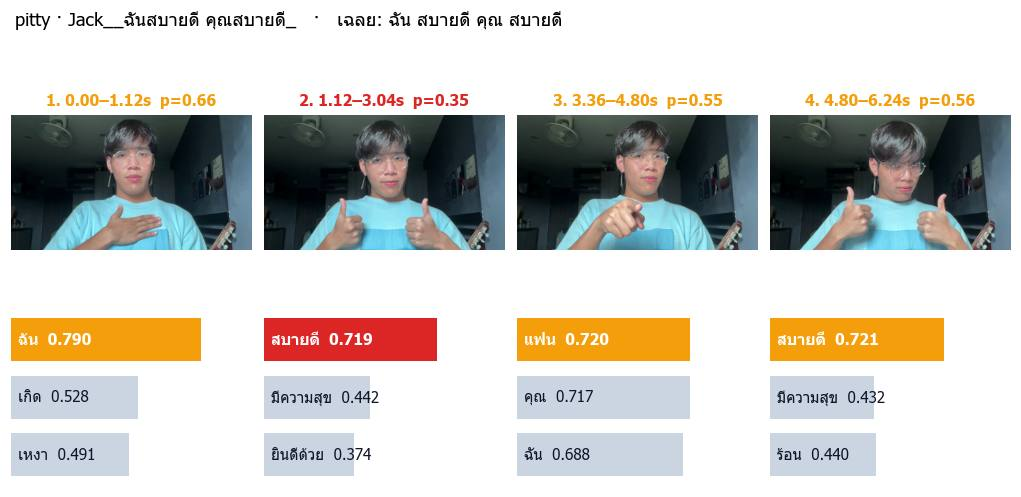

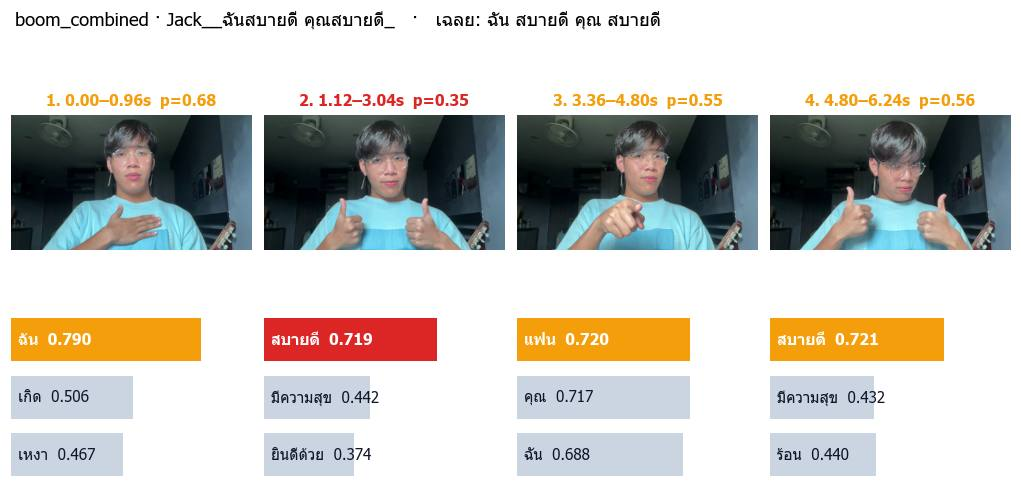

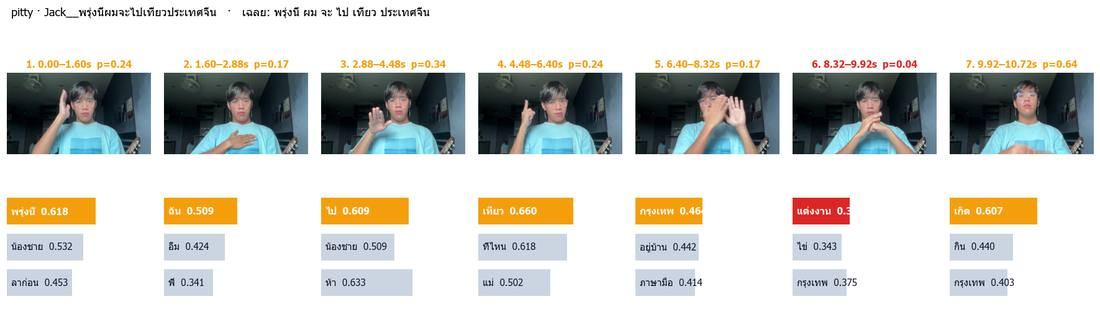

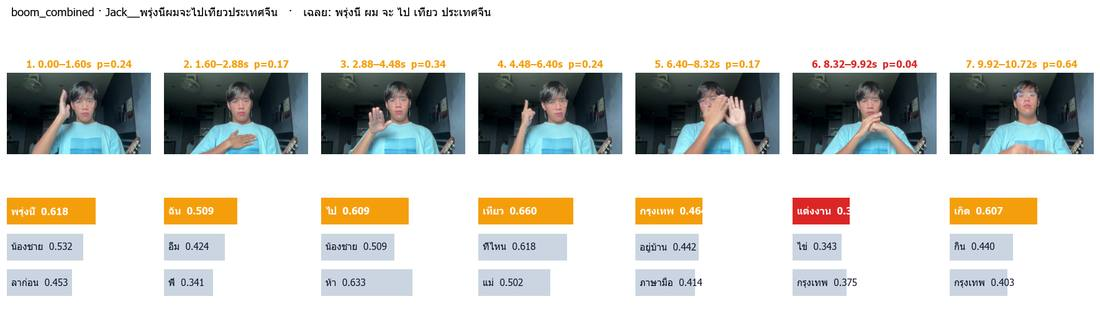

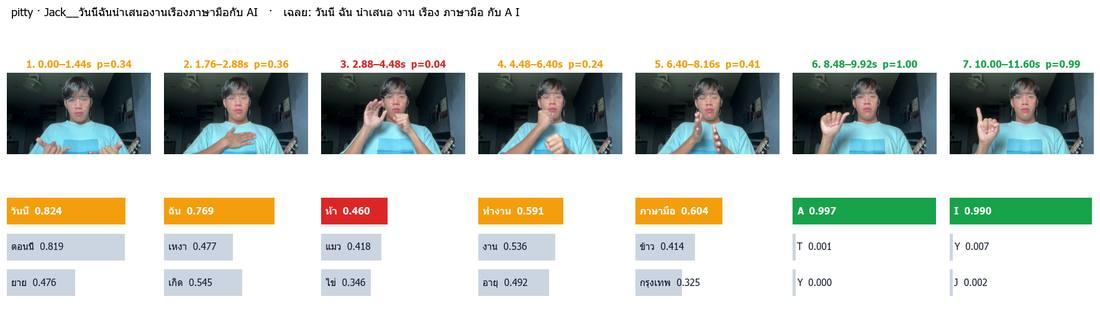

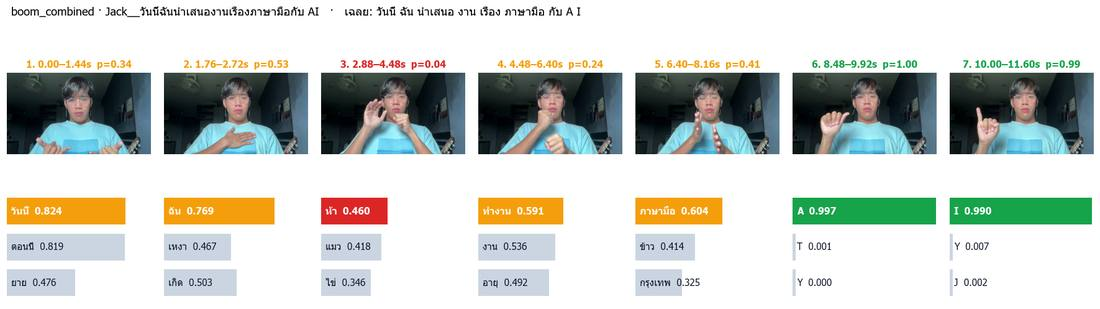

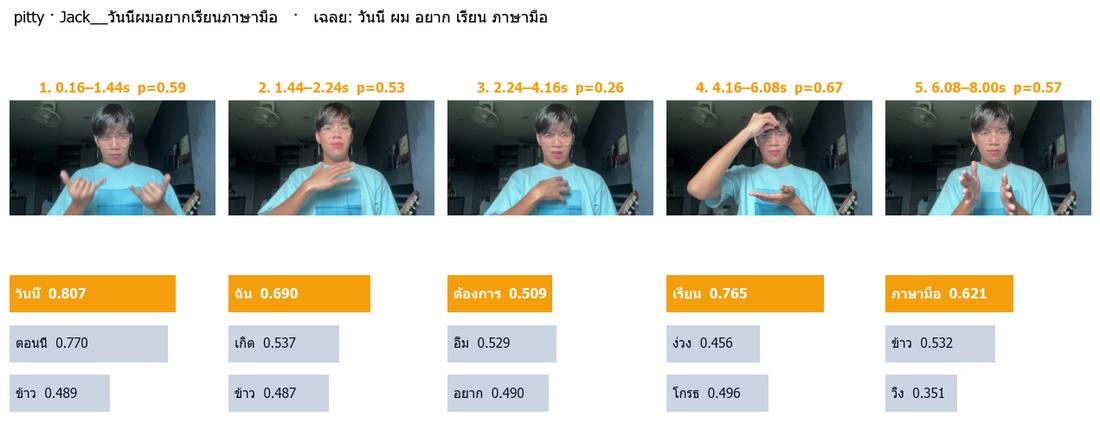

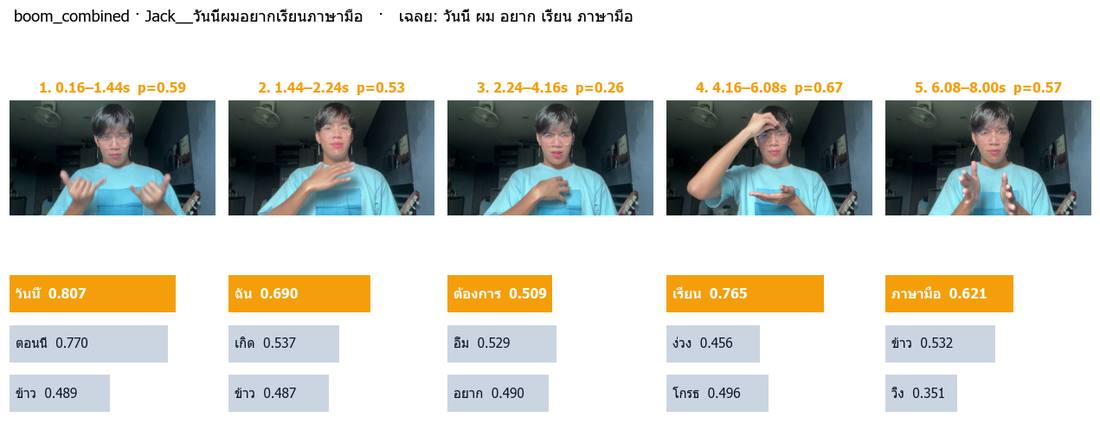

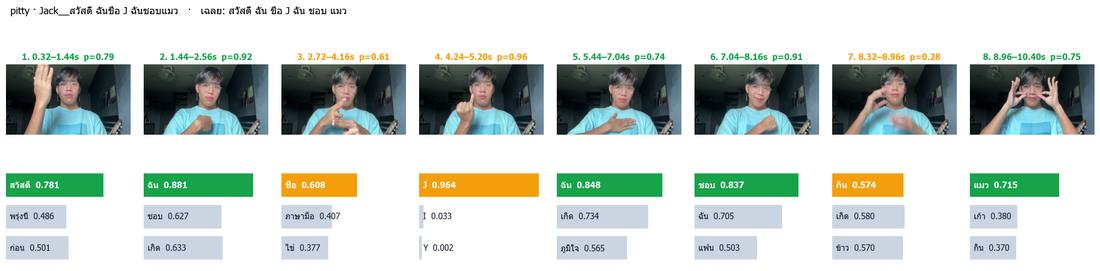

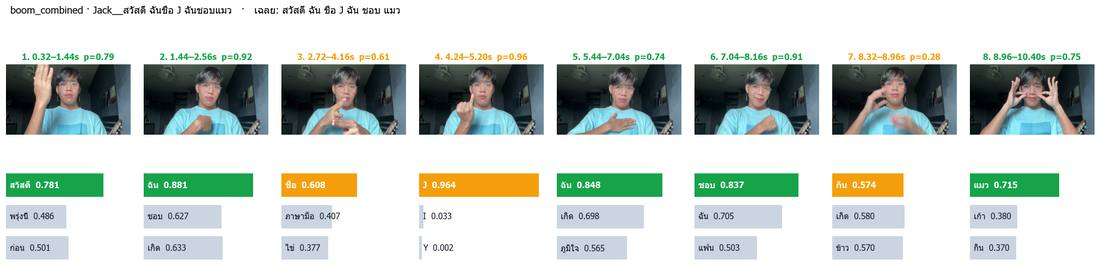

In [12]:
import io
from PIL import Image as PILImage

def small(f, width=1100):
    # ย่อ + JPEG ก่อนฝังใน notebook (PNG เต็มขนาดอยู่ใน cache/team_eval/results) → ไฟล์ notebook เล็กพอจะขึ้น Git
    im = PILImage.open(f).convert('RGB')
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    b = io.BytesIO(); im.save(b, 'JPEG', quality=72); return Image(data=b.getvalue(), format='jpeg')

for p in ['Pitty', 'Boom', 'Jack']:
    display(Markdown(f'### {p}'))
    for v in V[V.person == p].video.unique():
        k = f'{p}__{v}'
        for m in ['pitty', 'boom_combined']:
            f = E / 'results' / m / f'{k}_timeline.png'
            if f.exists():
                display(small(f))

## 5. สรุป

In [13]:
a = S.loc['ทั้งหมด 18 คลิป']
lines = [f"- **{m}**: WER {a.loc[m, 'WER (เฉลี่ยต่อคลิป)']:.3f} · ถูก {a.loc[m, 'ถูก']} · Recall@5 {a.loc[m, 'Recall@5']:.3f} · "
         f"ยืนยันถูก {a.loc[m, 'ยืนยันถูก']} · count error {a.loc[m, 'count error']:.2f} · latency {a.loc[m, 'latency (s, median)']:.2f}s" for m in order]
display(Markdown('\n'.join(lines)))

- **pitty**: WER 0.891 · ถูก 37/87 · Recall@5 0.494 · ยืนยันถูก 16/16 · count error 1.78 · latency 2.32s
- **boom_branch**: WER 0.891 · ถูก 38/87 · Recall@5 0.506 · ยืนยันถูก 10/10 · count error 1.83 · latency 2.29s
- **boom_combined**: WER 0.891 · ถูก 37/87 · Recall@5 0.494 · ยืนยันถูก 15/15 · count error 1.78 · latency 2.26s

**อ่านผล**

* น้ำหนักโมเดลเหมือนกัน และคำ top-1 แทบเหมือนกันทุกคลิป → **WER ของ pitty / boom_branch / boom_combined เท่ากันบน 18 คลิปนี้**
  ความต่างอยู่ที่ "ยืนยันคำได้กี่คำ": pitty กับ boom_combined ใช้เกณฑ์ยืนยัน 0.7 จึงยืนยันได้มากกว่า boom_branch (0.8) โดยคำที่ยืนยันยังถูกทุกคำ
* ต่างกันแค่ 2 คลิปของ Boom: "ตอนนี้กำลังเรียนภาษา" — โค้ด boom ได้คำถูกเพิ่ม 1 คำแต่ก็มีคำเกินเพิ่ม 1 คำ (WER เท่าเดิม);
  "เราจะเป็นเพื่อนกันตลอดไป" — boom_combined (act_thr 0.6) เสีย "เพื่อน" ไป 1 คำแต่คำเกินลด 1 คำ (WER เท่าเดิม)
* คลิปของ Boom WER > 1 ทุกโมเดล: คลิปยาว 12–15 วินาที มีช่วงพักก่อน/หลังทำภาษามือ (อ่านเป็นคำเกิน) และ 8 จาก 29 คำเฉลยไม่อยู่ใน vocab
  ตัวเลขนี้ไม่ใช่ข้อสรุปว่าโมเดลไหนดีกว่า — ต้องให้ Boom ยืนยันลำดับท่าในเฉลยก่อน
* คลิปของ Pitty ไม่ใช่ unseen test ของ pitty (เคยใช้ตั้งค่า phase 8) และคลิปของ Boom เคยใช้พัฒนาในงานของ Boom (ตาม inventory) — ชุดที่เป็นกลางที่สุดคือ Jack 5 คลิป
* 18 คลิปน้อยเกินจะบอกความต่างระดับนี้ได้อย่างมีนัยสำคัญ